# Layer 5 in practice: observables

This notebook executes the material of {doc}`../layer5_observables`: the
real-space statistics of a galaxy sample from one spectrum, the two Hankel
engines against each other, the radial kernels, angular spectra with a beam, and
one compiled data vector with its Jacobian.
It runs on a `pip install` of `ggah_mod` plus `matplotlib`.
Layers 3 to 5 are work in progress, and the notice they emit on import is silenced below.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

import warnings

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import ggah_mod
warnings.filterwarnings("ignore", category=ggah_mod.WorkInProgressWarning)

import ggah_mod.observables as OB
import ggah_mod.sectors as S
import ggah_mod.spectra as SP
from ggah_mod import ACCURATE, DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.calibration import MismatchWarning
from ggah_mod.halos.field import make_field, make_fields

warnings.filterwarnings("ignore", category=MismatchWarning)
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (6.4, 4.0),
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"ggah_mod {ggah_mod.__version__}, jax {jax.__version__}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod 1.7.0, jax 0.10.2


## The spectra

`zheng07` at its defaults on a field at $z = 0.25$, with a matter field whose hot
gas is a tenth of each halo's mass on the dark-matter profile.

In [2]:
pk = make_pk("emu_pk")
Z = 0.25
field = make_field(PLANCK18, DIFFERENTIABLE, pk, z=Z)
K = np.asarray(field.k)
gal, gp = S.GalaxySector("zheng07", backend=DIFFERENTIABLE), S.galaxy_defaults("zheng07")
split = S.BaryonSplit.from_hot(S.cosmic_baryon_fraction(PLANCK18), jnp.full(field.n_m, 0.1))
sectors = {"galaxies": gal, "matter": S.MatterField()}
params = {"galaxies": gp, "matter": {"split": split}}
p_gg = SP.spectrum(field, "galaxies", "galaxies", sectors, params)
p_gm = SP.spectrum(field, "galaxies", "matter", sectors, params)

## Real-space statistics and the two engines

*(a)* $\xi(r)$ and $w_p(r_p)$ at $\pi_{\max} = 60\,h^{-1}{\rm Mpc}$, *(b)*
$\Delta\Sigma(R)$, each by FFTLog (`DIFFERENTIABLE`, solid) and by Ogata's
quadrature (`ACCURATE`, dashed), on the same spectrum; *(c)* the ratio of the two
engines.

xi           max |FFTLog/quadrature - 1| over 0.1-30 h^-1 Mpc: 1.2e-03
wp           max |FFTLog/quadrature - 1| over 0.1-30 h^-1 Mpc: 4.0e-04
delta_sigma  max |FFTLog/quadrature - 1| over 0.1-30 h^-1 Mpc: 9.2e-05


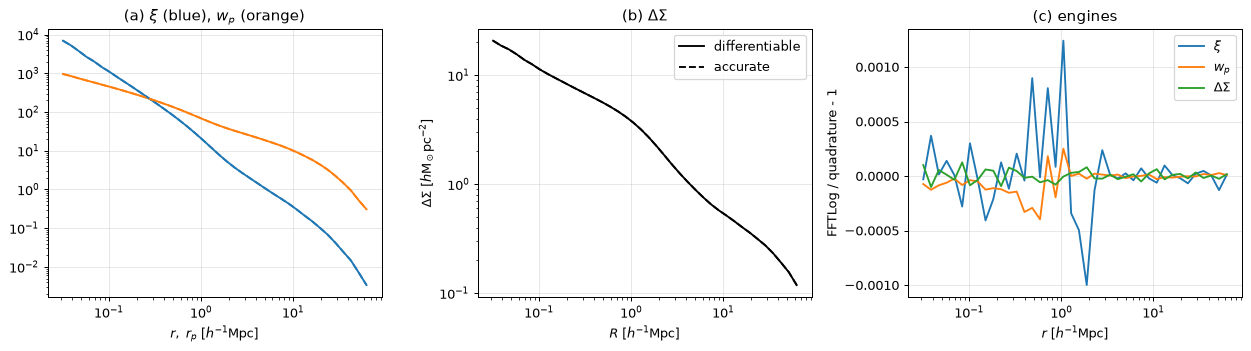

In [3]:
r = np.logspace(-1.5, 1.8, 40)
res = {}
for b in (DIFFERENTIABLE, ACCURATE):
    res[b.name] = (np.asarray(OB.xi(r, (K, p_gg.total), backend=b)),
                   np.asarray(OB.wp(r, (K, p_gg.total), pi_max=60.0, backend=b)),
                   np.asarray(OB.delta_sigma(r, (K, p_gm.total), PLANCK18, backend=b)))

fig, ax = plt.subplots(1, 3, figsize=(14.0, 4.0))
for name, ls in ((DIFFERENTIABLE.name, "-"), (ACCURATE.name, "--")):
    x_, w_, d_ = res[name]
    ax[0].loglog(r, x_, "C0" + ls); ax[0].loglog(r, w_, "C1" + ls)
    ax[1].loglog(r, d_, "k" + ls, label=name)
ax[0].set(xlabel=r"$r,\ r_p\ [h^{-1}{\rm Mpc}]$", title=r"(a) $\xi$ (blue), $w_p$ (orange)")
ax[1].set(xlabel=r"$R\ [h^{-1}{\rm Mpc}]$", ylabel=r"$\Delta\Sigma\ [h{\rm M}_\odot{\rm pc}^{-2}]$", title=r"(b) $\Delta\Sigma$")
ax[1].legend()
for i, lab in enumerate((r"$\xi$", r"$w_p$", r"$\Delta\Sigma$")):
    ax[2].semilogx(r, res[DIFFERENTIABLE.name][i] / res[ACCURATE.name][i] - 1, label=lab)
ax[2].set(xlabel=r"$r\ [h^{-1}{\rm Mpc}]$", ylabel="FFTLog / quadrature - 1", title="(c) engines")
ax[2].legend()
fig.tight_layout()
for i, lab in enumerate(("xi", "wp", "delta_sigma")):
    d = res[DIFFERENTIABLE.name][i] / res[ACCURATE.name][i] - 1
    print(f"{lab:12s} max |FFTLog/quadrature - 1| over 0.1-30 h^-1 Mpc: {np.max(np.abs(d[(r > 0.1) & (r < 30)])):.1e}")

## Kernels and angular spectra

*(a)* The radial kernels of a galaxy sample at $z = 0.5$, of sources at $z = 1$
and of the CMB, on the projection grid. *(b)* $C_\ell$ of the galaxies, of the
galaxies with the CMB lensing and with the galaxy lensing, from one compiled
model, and the galaxy spectrum under a $1'$ Gaussian beam (dashed).
*(c)* $w(\theta)$ of the galaxies.

224 numbers in the data vector


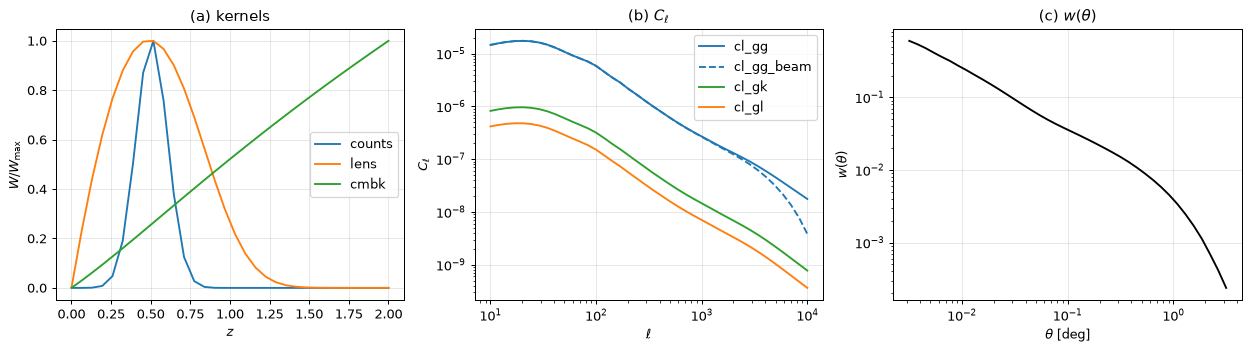

In [4]:
z, chi = OB.limber_grid(PLANCK18, z_max=2.0, backend=DIFFERENTIABLE)
zn = np.asarray(z)
kernels = {"counts": OB.number_counts(z, chi, np.exp(-0.5 * ((zn - 0.5) / 0.1) ** 2)),
           "lens": OB.lensing_efficiency(z, chi, np.exp(-0.5 * ((zn - 1.0) / 0.2) ** 2), PLANCK18),
           "cmbk": OB.cmb_lensing(z, chi, PLANCK18)}
beams = {"b1": lambda l: OB.gaussian(l, 60.0)}
ell = np.logspace(1.0, 4.0, 40)
theta = np.radians(np.logspace(-2.5, 0.5, 40))
rp = np.logspace(-1.0, 1.5, 12)
spec = OB.ObservableSpec((
    OB.Wp("wp", "galaxies", "galaxies", rp, pi_max=60.0, z=Z),
    OB.DeltaSigma("ds", "galaxies", "matter", rp, z=Z),
    OB.Cl("cl_gg", "galaxies", "galaxies", ell, kernel_a="counts", kernel_b="counts"),
    OB.Cl("cl_gg_beam", "galaxies", "galaxies", ell, kernel_a="counts", kernel_b="counts",
          beam_a="b1", beam_b="b1"),
    OB.Cl("cl_gk", "galaxies", "matter", ell, kernel_a="counts", kernel_b="cmbk"),
    OB.Cl("cl_gl", "galaxies", "matter", ell, kernel_a="counts", kernel_b="lens"),
    OB.WTheta("w", "galaxies", "galaxies", theta, kernel_a="counts", kernel_b="counts"),
))
model = jax.jit(OB.make_model(
    spec, fields_at=lambda zs: make_fields(PLANCK18, DIFFERENTIABLE, pk, zs),
    sectors=sectors, kernels=kernels, beams=beams, cosmo=PLANCK18,
    backend=DIFFERENTIABLE, z_proj=zn, k=K))
out, vector = model(params)

fig, ax = plt.subplots(1, 3, figsize=(14.0, 4.0))
for name, c in (("counts", "C0"), ("lens", "C1"), ("cmbk", "C2")):
    w = np.asarray(kernels[name].w)
    ax[0].plot(zn, w / w.max(), c, label=name)
ax[0].set(xlabel="$z$", ylabel=r"$W/W_{\max}$", title="(a) kernels")
ax[0].legend()
for key, ls in (("cl_gg", "C0"), ("cl_gg_beam", "C0--"), ("cl_gk", "C2"), ("cl_gl", "C1")):
    ax[1].loglog(ell, np.abs(np.asarray(out[key])), ls, label=key)
ax[1].set(xlabel=r"$\ell$", ylabel=r"$C_\ell$", title=r"(b) $C_\ell$")
ax[1].legend()
ax[2].loglog(np.degrees(theta), np.asarray(out["w"]), "k")
ax[2].set(xlabel=r"$\theta$ [deg]", ylabel=r"$w(\theta)$", title=r"(c) $w(\theta)$")
fig.tight_layout()
print(f"{vector.size} numbers in the data vector")

## The Jacobian of the data vector

The derivative of the whole vector with respect to the satellite slope `alpha`
of `zheng07`, by forward-mode differentiation through the compiled model,
against a central difference, for $w_p$ and $C_\ell^{\rm gg}$.

max |jacfwd - central difference| / max |jacfwd| = 6.5e-08


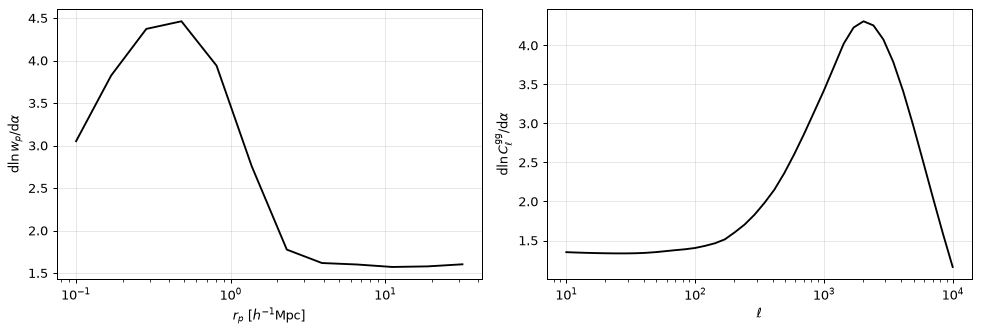

In [5]:
def vec(alpha):
    return model({"galaxies": gp | {"alpha": alpha}, "matter": params["matter"]})[1]

jac = np.asarray(jax.jacfwd(vec)(1.0))
fd = (np.asarray(vec(1.0 + 1e-4)) - np.asarray(vec(1.0 - 1e-4))) / 2e-4
print(f"max |jacfwd - central difference| / max |jacfwd| = {np.max(np.abs(jac - fd)) / np.max(np.abs(jac)):.1e}")

fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.8))
v = np.asarray(vector)
ax[0].semilogx(rp, jac[:12] / v[:12], "k")
ax[0].set(xlabel=r"$r_p\ [h^{-1}{\rm Mpc}]$", ylabel=r"${\rm d}\ln w_p/{\rm d}\alpha$")
sl = slice(24, 64)
ax[1].semilogx(ell, jac[sl] / v[sl], "k")
ax[1].set(xlabel=r"$\ell$", ylabel=r"${\rm d}\ln C^{\rm gg}_\ell/{\rm d}\alpha$")
fig.tight_layout()

## Things to try

- Pass `backend=ACCURATE` to `OB.wp` with a CLASS spectrum (`make_pk("class")`)
  for the fitting path.
- Swap the Gaussian beam for `OB.king(ell, *OB.beams.EROSITA_KING)`.
- Add a `Cl` of the thermal SZ: give the sector dictionary a `HotGasDPM` and the
  kernels an `OB.thermal_sz(z, chi)`, and cross `galaxies` with `pressure`.
- Change `pi_max` and follow $w_p$ on large scales.

Previous: {doc}`layer4_spectra`. Next: {doc}`layer6_covariance`.